# 22 · Supersampling a fit with long exposures

**Level:** beginner · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb) · **Run time:** ~1 min

**Covers:** why a long exposure smears a transit, what happens to the fit if the model ignores it, and
`supersample_factor="auto"` with `exp_time` in `MarginalTransitModel`.

A Kepler long-cadence point is not a snapshot: the camera adds up the light of the star for 29.4 minutes and records the
average. The ingress and egress of a transit last only minutes, so the recorded dip is smeared: its corners are rounded.
A model that is computed only at the middle of each exposure has sharp corners, and the fit then bends the planet's
parameters until the sharp model looks like the smeared data.

The fix is supersampling: compute the model at several times inside each exposure and average them. pizzetti does not
do this by default. Below we fit the same Kepler light curve of TrES-2 b (Kepler-1 b) twice, with the same code: first
without supersampling, then with `supersample_factor="auto"`. The two fits differ in one line.

In [1]:
import warnings
warnings.filterwarnings("ignore", module="lightkurve")   # lightkurve warns about an optional package
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from wotan import flatten, transit_mask
import pizzetti

## Step 1: the light curve

One quarter (Q3) of Kepler long-cadence data of TrES-2 b, a hot Jupiter on a 2.47-day orbit. We detrend it as in
tutorial 11 and keep the points near the transits.

350 points near the transits, noise 53 ppm per point


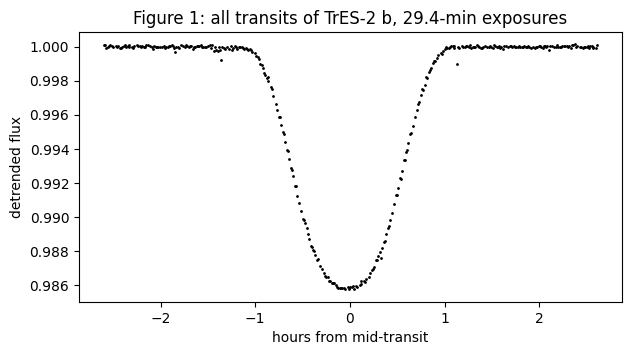

In [2]:
search = lk.search_lightcurve("Kepler-1", mission="Kepler", author="Kepler", exptime=1800, quarter=3)
lc = search.download().remove_nans().normalize()
time = lc.time.value          # days (BKJD = BJD - 2454833)
flux = lc.flux.value

period = 2.47063              # days
t0 = 122.76336                # a mid-transit time (BKJD)
duration = 1.74 / 24          # days
exp_time = 1765.5 / 86400     # the exposure of Kepler long cadence: 1765.5 s = 29.4 min, in days

mask = transit_mask(time=time, period=period, duration=1.5 * duration, T0=t0)
flat_flux = flatten(time, flux, method="biweight", window_length=2.0, mask=mask)
ok = np.isfinite(flat_flux)
time, flat_flux = time[ok], flat_flux[ok]
phase = (time - t0 + 0.5 * period) % period - 0.5 * period      # days from mid-transit
near = np.abs(phase) < 1.5 * duration
sigma = np.std(flat_flux[np.abs(phase) > duration])              # noise per point
print(f"{near.sum()} points near the transits, noise {sigma * 1e6:.0f} ppm per point")

plt.figure(figsize=(7, 3.5))
plt.plot(24 * phase[near], flat_flux[near], "k.", ms=2)
plt.xlabel("hours from mid-transit"); plt.ylabel("detrended flux")
plt.title("Figure 1: all transits of TrES-2 b, 29.4-min exposures");

## Step 2: first guesses

The same for both fits.

In [3]:
params = pizzetti.TransitParams()
params.t0 = t0                    # first guesses
params.per = period
params.rp = 0.125
params.a = 7.6
params.inc = 83.6                 # degrees
params.ecc = 0.0
params.w = 90.0
params.limb_dark = "quadratic"
params.u = [0.4, 0.25]

## Step 3: fit A, without supersampling

This is the fit of tutorial 11. The bound on Rp/R★ keeps the fit from running along the grazing solutions of this
high-impact-parameter transit. (`%%time` prints how long the cell took.)

In [4]:
%%time
model_a = pizzetti.MarginalTransitModel(params, time[near], flat_flux[near], sigma, free=["t0", "rp", "a", "b"],
                                        bounds={"rp": (0.01, 0.5)})
result_a = model_a.fit(ld="u", seed=1)
print(result_a.summary())

              median     -1sigma     +1sigma
t0          122.7621    1.19e-05     1.2e-05
rp          0.137986    0.000393    0.000552
a           7.273161      0.0176      0.0232
b          0.8094065     0.00259     0.00263
u1          1.643535      0.0268      0.0263
u2        -0.6550577      0.0356      0.0309
f0          0.999967    3.74e-06    3.54e-06
CPU times: user 355 ms, sys: 12.1 ms, total: 367 ms
Wall time: 367 ms


<timed exec>:3: UserWarning: no exp_time given: if each point is an exposure as long as the cadence (29.4 min), the model without exposure average is off by chi^2 = 2.3e+04 at the posterior median, which can move the posterior by up to ~152 sigma; pass exp_time=0.020433 with supersample_factor=37 (or "auto"); if the exposures are shorter, pass their exp_time (tutorial 22)


The fit runs, but pizzetti warns. It was not told the exposure time, so after the fit it assumes that each point is
an exposure as long as the time between the points (true for Kepler and TESS), and computes how far the model is from
the exposure average at the fitted parameters. Here it is far off, and the warning says how many sub-exposures the fit
needs.

## Step 4: fit B, with supersampling

The same code, with `supersample_factor="auto"` and the exposure time `exp_time` added. "auto" computes how many
sub-exposures this light curve needs; `model_b.k` shows the number.

In [5]:
%%time
model_b = pizzetti.MarginalTransitModel(params, time[near], flat_flux[near], sigma, free=["t0", "rp", "a", "b"],
                                        bounds={"rp": (0.01, 0.5)}, supersample_factor="auto", exp_time=exp_time)
result_b = model_b.fit(ld="u", seed=1)
print(result_b.summary())
print("sub-exposures per point:", model_b.k)

              median     -1sigma     +1sigma
t0          122.7621    1.16e-05    1.14e-05
rp         0.1252137     0.00152     0.00244
a           7.909252      0.0924       0.115
b          0.8444588       0.012     0.00935
u1         0.3829098        0.27       0.355
u2         0.2035356       0.409       0.339
f0         0.9999792    3.55e-06    3.65e-06
sub-exposures per point: 31
CPU times: user 5.25 s, sys: 2.51 ms, total: 5.25 s
Wall time: 5.25 s


No warning this time. That is all you need: for exposures longer than a few minutes, add
`supersample_factor="auto", exp_time=...` to `MarginalTransitModel`.

The rest of this tutorial compares the two results. The code from here on is longer, but you do not need it for your
own fits.

## Step 5: the two results side by side

The table lists the median and the 1σ range of each parameter, and how far fit A's median lies from fit B's, in units of
fit B's standard deviation. T14 (hours), the duration from first to last contact, is computed from rp, a and b.

In [6]:
def columns(result):
    S = dict(zip(result.labels, result.samples.T))
    rp, a, b = S["rp"], S["a"], np.abs(S["b"])
    S["T14"] = 24 * period / np.pi * np.arcsin(np.sqrt(np.clip((1 + rp) ** 2 - b ** 2, 0, None)) / np.sqrt(a ** 2 - b ** 2))
    return S

SA, SB = columns(result_a), columns(result_b)
print(f"{'':5s} {'fit A (no supersampling)':>27s} {'fit B (auto, k = ' + str(model_b.k) + ')':>27s} {'A - B':>9s}")
for name in ["rp", "a", "b", "u1", "u2", "T14"]:
    qa = np.percentile(SA[name], [16, 50, 84])
    qb = np.percentile(SB[name], [16, 50, 84])
    shift = (qa[1] - qb[1]) / (0.5 * (qb[2] - qb[0]))
    print(f"{name:5s} {qa[1]:12.4f} +{qa[2] - qa[1]:.4f} -{qa[1] - qa[0]:.4f} "
          f"{qb[1]:12.4f} +{qb[2] - qb[1]:.4f} -{qb[1] - qb[0]:.4f} {shift:+8.1f} σ")

         fit A (no supersampling)        fit B (auto, k = 31)     A - B
rp          0.1380 +0.0006 -0.0004       0.1252 +0.0024 -0.0015     +6.5 σ
a           7.2732 +0.0232 -0.0176       7.9093 +0.1150 -0.0924     -6.1 σ
b           0.8094 +0.0026 -0.0026       0.8445 +0.0093 -0.0120     -3.3 σ
u1          1.6435 +0.0263 -0.0268       0.3829 +0.3549 -0.2696     +4.0 σ
u2         -0.6551 +0.0309 -0.0356       0.2035 +0.3390 -0.4091     -2.3 σ
T14         2.0937 +0.0064 -0.0090       1.7877 +0.0156 -0.0115    +22.6 σ


Without supersampling the fit makes the transit longer (T14 2.09 h instead of 1.79 h, 23 σ off) and deeper (Rp/R★
0.138 instead of 0.125), with a smaller a/R★ and b. It also pushes the limb darkening to extreme values (u1 ≈ 1.6,
u2 ≈ −0.66) to round off the bottom of its sharp model. Its error bars are about four times narrower than fit B's: the
result is precise, and wrong, because its error bars do not include the error of the model.

## Step 6: the two best fits on the data

By eye, both best fits follow the data. The residuals, averaged in 10-minute bins, show the difference.

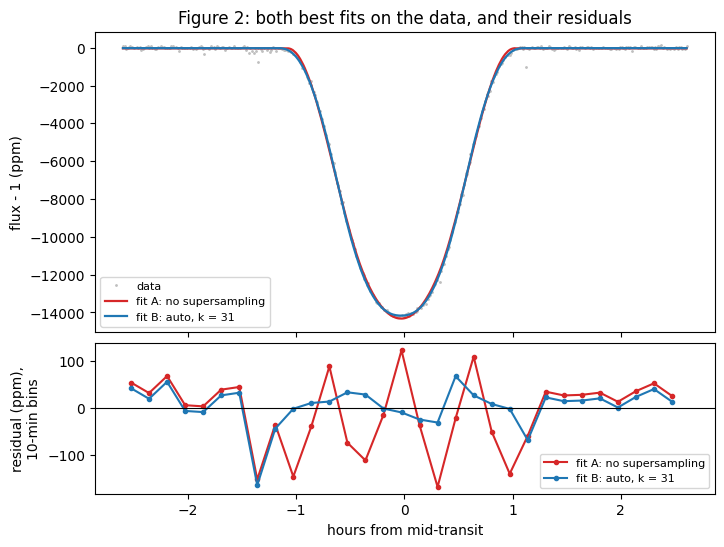

In [7]:
def best_model(result, model):
    best = dict(zip(result.labels, np.median(result.samples, axis=0)))
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = best["t0"], period, best["rp"], best["a"]
    p.inc = np.degrees(np.arccos(abs(best["b"]) / best["a"]))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [best["u1"], best["u2"]]
    m = pizzetti.TransitModel(p, time[near], supersample_factor=model.k, exp_time=exp_time if model.k > 1 else 0.0,
                              offsets="midpoint")
    return best["f0"] * m.light_curve(p)

ph, f = phase[near], flat_flux[near]
order = np.argsort(ph)
bins = np.arange(-1.5 * duration, 1.5 * duration + 1e-9, 10 / 1440)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=(2, 1), hspace=0.05))
ax[0].plot(24 * ph, 1e6 * (f - 1), ".", color="0.75", ms=2, label="data")
for result, model, color, label in [(result_a, model_a, "C3", "fit A: no supersampling"),
                                    (result_b, model_b, "C0", f"fit B: auto, k = {model_b.k}")]:
    m = best_model(result, model)
    ax[0].plot(24 * ph[order], 1e6 * (m[order] - 1), color=color, lw=1.6, label=label)
    which = np.digitize(ph, bins)
    binned = [np.mean((f - m)[which == i]) if np.any(which == i) else np.nan for i in range(1, len(bins))]
    ax[1].plot(24 * 0.5 * (bins[1:] + bins[:-1]), 1e6 * np.array(binned), "o-", color=color, ms=3, label=label)
ax[1].axhline(0, color="k", lw=0.8)
ax[0].set_ylabel("flux - 1 (ppm)"); ax[1].set_ylabel("residual (ppm),\n10-min bins")
ax[1].set_xlabel("hours from mid-transit"); ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
ax[0].set_title("Figure 2: both best fits on the data, and their residuals");

Fit A's residuals swing by about ±150 ppm through the transit: a sharp model cannot take the shape of a smeared dip.
Fit B's stay within the noise. (The two low bins outside the transit are the same in both fits: a few outlying points.)

## Step 7: the posteriors

Both posteriors in one corner plot.

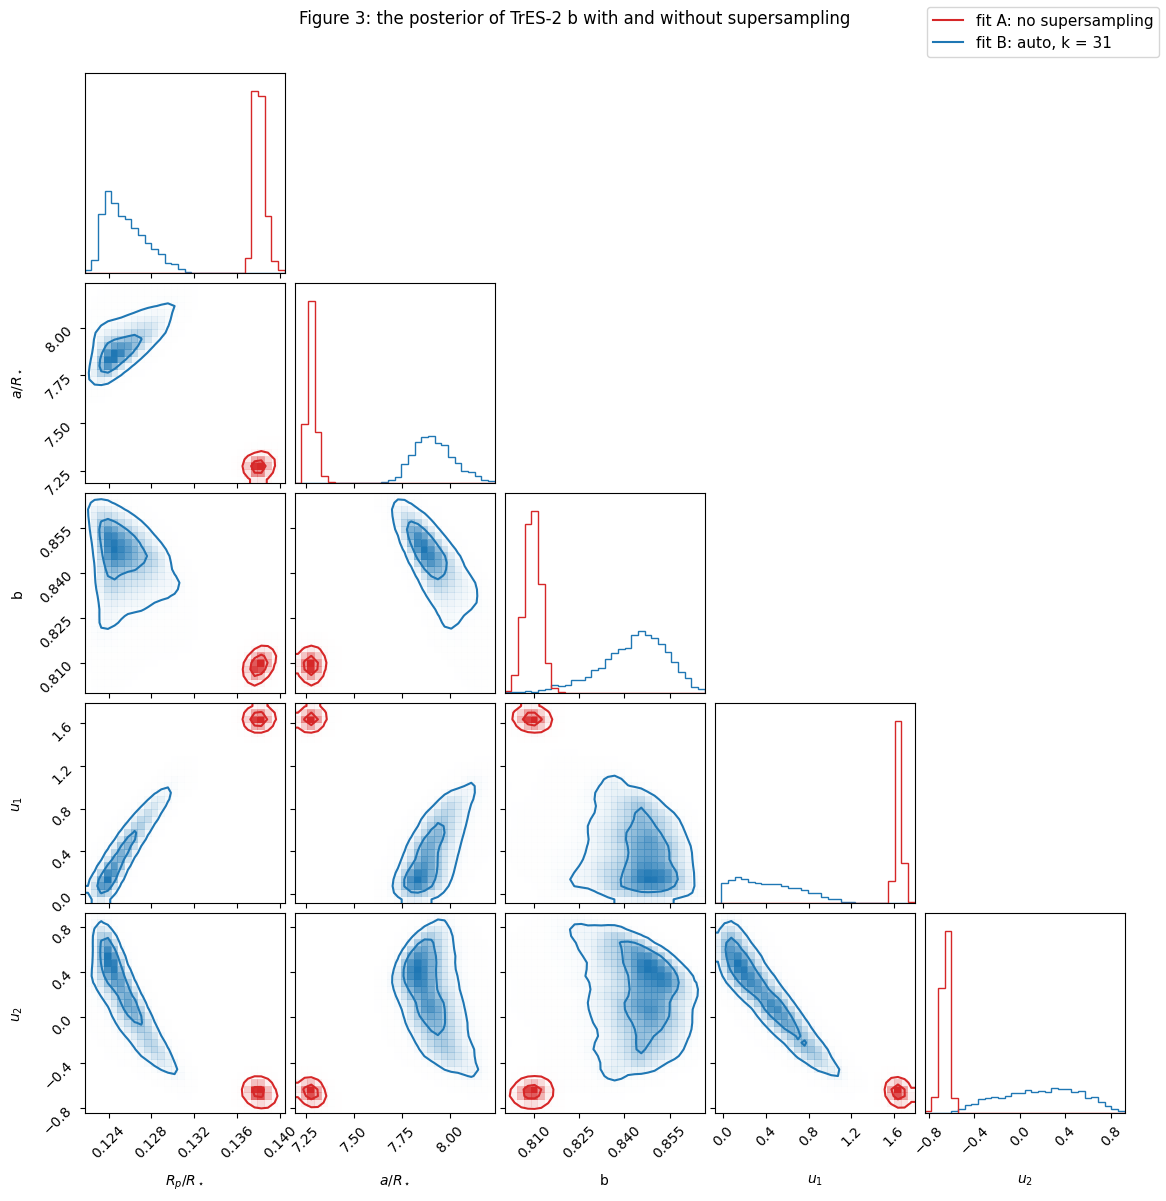

In [8]:
import corner
names = ["rp", "a", "b", "u1", "u2"]
XA = np.column_stack([np.abs(SA[n]) if n == "b" else SA[n] for n in names])
XB = np.column_stack([np.abs(SB[n]) if n == "b" else SB[n] for n in names])
both = np.vstack([XA, XB])
lo, hi = np.percentile(both, 0.5, axis=0), np.percentile(both, 99.5, axis=0)
ranges = list(zip(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo)))
options = dict(range=ranges, plot_datapoints=False, smooth=1.0, levels=(0.39, 0.86), bins=30)
fig = corner.corner(XB, labels=[r"$R_p/R_\star$", r"$a/R_\star$", "b", "$u_1$", "$u_2$"], color="C0", **options)
corner.corner(XA, color="C3", fig=fig, **options)
fig.legend(handles=[plt.Line2D([], [], color="C3", label="fit A: no supersampling"),
                    plt.Line2D([], [], color="C0", label=f"fit B: auto, k = {model_b.k}")], loc="upper right", fontsize=11)
fig.suptitle("Figure 3: the posterior of TrES-2 b with and without supersampling", y=1.02);

The two posteriors do not overlap. Neither the noise nor the limb darkening, which both fits integrate out, can make up
for the missing exposure average.

## Step 8: how "auto" chooses the number of sub-exposures

What matters is not the error of the model at one point but its effect on the fit, summed over all points:
χ² = Σ (f_k − f_exact)² / σ², where f_k is the model with k sub-exposures and f_exact a model with many more. A model
error of χ² can move the posterior by at most about √χ² standard deviations (usually much less). "auto" computes this χ²
at the first guesses, for k = 1, 2, 3, ..., and takes the first k with χ² ≤ 0.01, a shift of at most 0.1 σ. The values
it tried are in `model_b.supersample_table`. After the fit, pizzetti computes χ² again at the fitted parameters and
stores it in `result.diagnostics["supersample_chi2"]`; it warns if χ² > 0.1.

In [9]:
for k, chi2 in model_b.supersample_table.items():
    print(f"k = {k:3d}   chi2 = {chi2:10.4g}")
print("fit A, chi2 at its fitted parameters:", f"{result_a.diagnostics['supersample_chi2']:.4g}")
print("fit B, chi2 at its fitted parameters:", f"{result_b.diagnostics['supersample_chi2']:.4g}")

k =   1   chi2 =  1.712e+04
k =   2   chi2 =      754.1
k =   3   chi2 =      141.5
k =   4   chi2 =      43.09
k =   5   chi2 =      16.89
k =   6   chi2 =      8.008
k =   8   chi2 =      2.481
k =  10   chi2 =     0.9843
k =  12   chi2 =     0.4678
k =  15   chi2 =     0.1804
k =  18   chi2 =    0.08658
k =  21   chi2 =    0.04671
k =  25   chi2 =    0.02357
k =  31   chi2 =   0.009823
fit A, chi2 at its fitted parameters: 2.3e+04
fit B, chi2 at its fitted parameters: 0.01071


Without supersampling (k = 1) the model is off by χ² ≈ 17 000 at the first guesses. The error falls quickly with k. A
common rule of thumb, one sub-exposure per 2 minutes of exposure (k = 15 here), still leaves χ² ≈ 0.18 for these 350
precise points. This light curve needs 31.

Fit A's warning asks for 37 rather than 31 because it computes χ² at fit A's own, wrong parameters. The shift in its
warning (about 150 σ) is an upper bound; the actual shift was 23 σ.

To choose k yourself, for example for `TransitModel` or another fitting code, use the same function as "auto":
`k = pizzetti.choose_supersample(params, t, exp_time, sigma)`.

## Step 9: the cost

Supersampling computes the model at k times as many points, so each likelihood evaluation costs more.

In [10]:
for name, result, model in [("fit A", result_a, model_a), ("fit B", result_b, model_b)]:
    print(f"{name}: k = {model.k:2d}, {near.sum() * model.k:6d} model points, "
          f"{result.diagnostics['n_eval']:6d} likelihood evaluations")

fit A: k =  1,    350 model points,   9352 likelihood evaluations
fit B: k = 31,  10850 model points,  31170 likelihood evaluations


Fit B computes the model at 31 times as many points and took about 5 s instead of 0.4 s (see `%%time` in Steps 3
and 4). For a few hundred points that is still quick.

## What you learned

- A long exposure averages the light curve. A fit that ignores it does not fail: it gives a precise result in the wrong
  place, here a longer, deeper transit with extreme limb darkening, T14 off by 23 σ.
- `MarginalTransitModel(..., supersample_factor="auto", exp_time=...)` chooses the number of sub-exposures for your light
  curve. `exp_time` is in days.
- Without supersampling, pizzetti checks after the fit and warns if it was needed. With supersampling, it checks that k
  was large enough.
- For exposures of 2 minutes or less (TESS 2-min, Kepler short cadence), supersampling is usually not needed; the check
  after the fit tells you.

**Next:** [04](04_observing_realities.ipynb) shows long exposures on the light-curve side (`TransitModel`);
[17](17_the_grand_tour.ipynb) runs the whole chain from download to posterior.